# 1. Import libraries and Config

In [4]:
import torch
import torch.nn as nn
import torchvision
from torchinfo import summary
from torchvision import transforms

from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))
import importlib

# my Modules 
from M02_Modularity.going_modular import data_setup, model_builder, utils, evaluation

### Color configure

In [10]:
RED = "\033[31m"
GREEN = "\033[32m"
YELLOW = "\033[33m"
BLUE = "\033[34m"
MAGENTA = "\033[35m"
CYAN = "\033[36m"
ORANGE = "\033[38;5;208m"
BOLD = "\033[1m"
RESET = "\033[0m"

In [19]:
# Device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"I'll be using {BOLD}{ORANGE}{device} {RESET}device")

I'll be using cpu device


# 2. Pre-Processing
### 2.1 Get the Data

In [26]:
# Data directory
Food_Dir = ROOT_DIR / "Dataset//pizza_steak_sushi"
train_data_dir = Food_Dir / "train"
test_data_dir = Food_Dir / "test"

dataset_dir = Food_Dir.parent

### 2.2. Turn to DataLoader

In [27]:
# We can create transform using manually or automaticcally. wehen manually it is more customze and best but there is one problem the pretrained model will not much. and the authomatic is fine with pretrained model but it is rigid there is not change to customize.
weight = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transform = weight.transforms()

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
                                                train_dir=train_data_dir,
                                                test_dir=test_data_dir,
                                                train_transform=auto_transform,
                                                test_transform=auto_transform,
                                                batch_size=32,
                                                num_workers=0
                                            )
display(auto_transform)
train_dataloader, test_dataloader, class_names

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

(<torch.utils.data.dataloader.DataLoader at 0x7c6508936900>,
 ['pizza', 'steak', 'sushi'])

# 3. Get Pre-Trained and Train Model
### 3.1 Get Pre-Trained Model

In [28]:
model = torchvision.models.efficientnet_b0(weights=weight).to(device)
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [29]:
# Then freeze the model parameters extractor
for param in model.features.parameters():
    param.requires_grad = False

# seed for reproducibility
import src.helper as helper
helper = importlib.reload(helper)

helper.set_seed(42)

# Update the classifier head
model.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280, 
                    out_features=len(class_names), bias=True)
).to(device)

In [10]:
summary(model, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape" (batch_size, color_channels, height, width)
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

### 3.2 Train and Track Pre-Train Model

In [11]:
# Define loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [12]:
try:
    from torch.utils.tensorboard import SummaryWriter
except:
    print("[INFO] Couldn't find tensorboard... installing it.")
    %pip install -q tensorboard
    from torch.utils.tensorboard import SummaryWriter

In [13]:
writer = SummaryWriter()
from src import engine

# Train the model with new Updated script
result = engine.train_model(
                    model=model,
                    train_dataloader=train_dataloader,
                    test_dataloader=test_dataloader,
                    optimizer=optimizer,
                    loss_fn=loss_fn,
                    epochs=5,
                    device=device,    
                    writer=writer) 

writer.close()

/home/nigatie/Documents/ML_DL/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 20%|██        | 1/5 [00:20<01:23, 20.84s/it]

Epoch: 1 | train_loss: 1.0670 | train_accu: 0.4062 | test_loss: 0.8663 | test_accu: 0.6629


 40%|████      | 2/5 [00:40<01:00, 20.04s/it]

Epoch: 2 | train_loss: 0.8465 | train_accu: 0.7305 | test_loss: 0.6803 | test_accu: 0.8750


 60%|██████    | 3/5 [01:00<00:40, 20.28s/it]

Epoch: 3 | train_loss: 0.8058 | train_accu: 0.6367 | test_loss: 0.6368 | test_accu: 0.8646


 80%|████████  | 4/5 [01:20<00:19, 19.88s/it]

Epoch: 4 | train_loss: 0.6544 | train_accu: 0.8398 | test_loss: 0.6719 | test_accu: 0.7841


100%|██████████| 5/5 [01:39<00:00, 19.87s/it]

Epoch: 5 | train_loss: 0.7053 | train_accu: 0.7031 | test_loss: 0.6773 | test_accu: 0.7434


In [14]:
result

{'train_loss': [1.0670463293790817,
  0.8464927896857262,
  0.8058259338140488,
  0.6543662697076797,
  0.7052738890051842],
 'train_accu': [0.40625, 0.73046875, 0.63671875, 0.83984375, 0.703125],
 'test_loss': [0.8662561376889547,
  0.6802615920702616,
  0.6368398070335388,
  0.6719426115353903,
  0.6772668957710266],
 'test_accu': [0.662878787878788,
  0.875,
  0.8645833333333334,
  0.7840909090909092,
  0.743371212121212]}

In [15]:
%load_ext tensorboard
%tensorboard --logdir runs

Launching TensorBoard...

### 3.3 Create Helper Function

In [16]:
# By creating helper function we can build SummetryWriter() instance.
"""Summerywiter() are a method which is used for log and track what is happning on the model while training the model. it is directly specified by log_dir() method."""
print()

In [5]:
# setup the directory of the SummeryWriter() instance using helper function.
Log_path = ROOT_DIR / "Experiment_Tracker"

# Custom_writer = helper.create_writer(root_dir = Log_path,                   # type: ignore
#                                      experiment_name = "First_Experiment", 
#                                      model_name = "efficientnet_b0", 
#                                      extra = "Nigatie")

# Download dataset

In [18]:
data_setup = importlib.reload(data_setup)

# setup the data path to download 20% of the data if not exist.
image_path = dataset_dir / "pizza_steak_sushi_20_percent"

data_setup.check_data(data_path=dataset_dir,
                     image_path=image_path,
                     url="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")

/home/nigatie/Documents/ML_DL/B_Deep_Learning/Dataset directory already exists, skipping download.


In [19]:
# train and test dataset for the both 100% and 20% data
train_10_percent_data = dataset_dir / "pizza_steak_sushi/train"
train_20_percent_data = dataset_dir / "pizza_steak_sushi_20_percent/train"


# for test data
test_10_percent_data = dataset_dir / "pizza_steak_sushi/test"

print(f"Train 10% data: {train_10_percent_data}")
print(f"Train 20% data: {train_20_percent_data}")
print(f"Test 10% data: {test_10_percent_data}")

Train 10% data: /home/nigatie/Documents/ML_DL/B_Deep_Learning/Dataset/pizza_steak_sushi/train
Train 20% data: /home/nigatie/Documents/ML_DL/B_Deep_Learning/Dataset/pizza_steak_sushi_20_percent/train
Test 10% data: /home/nigatie/Documents/ML_DL/B_Deep_Learning/Dataset/pizza_steak_sushi/test


In [21]:
# Create a transform to normalize data distribution to be inline with ImageNet
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], # values per colour channel [red, green, blue]
                                 std=[0.229, 0.224, 0.225]) # values per colour channel [red, green, blue]

# Compose transforms into a pipeline
simple_transform = transforms.Compose([
    transforms.Resize((224, 224)),                          
    transforms.ToTensor(), 
   normalize
])

In [58]:
BATCH_SIZE = 32
data_setup = importlib.reload(data_setup)

# Create 10% training and test DataLoaders
train_dataloader_10_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_10_percent_data,
                                                                                        test_dir=test_10_percent_data, 
                                                                                        train_transform=simple_transform,
                                                                                        test_transform=simple_transform,
                                                                                        batch_size=BATCH_SIZE,
                                                                                        num_workers=4
                                                                                    )

# Create 20% training and test data DataLoders
train_dataloader_20_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_20_percent_data,
                                                                                            test_dir=test_10_percent_data,
                                                                                            train_transform=simple_transform,
                                                                                            test_transform=simple_transform,
                                                                                            batch_size=BATCH_SIZE,
                                                                                            num_workers=4
                                                                                        )

# Find the number of samples/batches per dataloader (using the same test_dataloader for both experiments)
print(f"Number of batches of size {BATCH_SIZE} in 10 percent training data: {len(train_dataloader_10_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in 20 percent training data: {len(train_dataloader_20_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in testing data: {len(test_dataloader)} (all experiments will use the same test set)")
print(f"Number of classes: {len(class_names)}, class names: {class_names}")

Number of batches of size 32 in 10 percent training data: 8
Number of batches of size 32 in 20 percent training data: 15
Number of batches of size 32 in testing data: 3 (all experiments will use the same test set)
Number of classes: 3, class names: ['pizza', 'steak', 'sushi']


In [ ]:
# The given image will be have the size of (32, 2, 224, 224): this means at the time there are 32 images and those image of three channels and the numbers are the height and the width of the image.

In [20]:
# Assign efficientnet_b2 model weghts
effnetb0_weight = torchvision.models.EfficientNet_B0_Weights.DEFAULT
effnetb2_weight = torchvision.models.EfficientNet_B2_Weights.DEFAULT

# Then  Assign the model of the given weights
effnetb0 = torchvision.models.efficientnet_b0(weights=effnetb0_weight).to(device)
effnetb2 = torchvision.models.efficientnet_b2(weights=effnetb2_weight).to(device)

In [29]:
from torchinfo import summary

summary(effnetb2,
        input_size=(32, 3, 224, 224), 
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [25]:
print(f"The number of input features for the last classifier layer of the model are: {effnetb2.classifier[1].in_features}")

The number of input features for the last classifier layer of the model are: 1408


In [26]:
# Now we need one helper function to setup the in_feature and out_features of the two models(efficientnet_b0 and efficientnet_b2) to make them ready for training.
"""What the helper function do are: 
1. Gat the base model,
2. Freeze the base model parameters(layers).
3. Set randomness seed for reproducibility.
4. Change the classifier head of the model as we need.
5. Give the model namge and experiment name to the SummeryWriter() instance.
"""
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [30]:
helper = importlib.reload(helper)

model_01 = helper.create_model(model_name="efficientnet_b0",
                               model=effnetb0,
                               in_features=1280,
                               out_features=len(class_names))    
model_02 = helper.create_model(model_name="efficientnet_b2",
                               model=effnetb2,  
                                 in_features=1408,
                                 out_features=len(class_names))
print(f"{GREEN}Model 01: {RESET}{model_01}")
print(f"{GREEN}Model 02: {RESET}{model_02}")

[INFO] New model efficientnet_b0 Created with 1280 input features and 3 output features.
[INFO] New model efficientnet_b2 Created with 1408 input features and 3 output features.
Model 01: EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
           

In [35]:
summary(model=model_01,
         input_size=(32, 3, 224, 224),
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"]
         )

summary(model=model_02,
         input_size=(32, 3, 224, 224),
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"]
         )

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [59]:
# Our number of Epochs for training and experimenting.
num_epochs = [5, 10]

# Created models
models = ["effnetb0", "effnetb2"]

# We have dataset
train_dataloaders = [train_dataloader_10_percent, train_dataloader_20_percent]

In [ ]:
# steps we will follow for training and evaluating the model:
"""
1. Set the random seed for reproducibility.
2. Keep track of different experiment.
3. Loop through trainloaders
4. Loop through epochs
5. Loop through the list of models
6. Create infrormation print out what is going on the training of models
7. Check which model is performing better and why?
8. Create loss function and optimizer for each model and each experiment.
9. Train the model with modified train function with aproprate detail and writer parameters.
10. save the model with aproprate model name and experiment name.
"""


"""
I have to inport:
from engine.py train_model() function and its arg:
        -model
        -trian_dataloader
        -test_dataloader
        -optimizer
        -loss_fn
        -epochs
        -device
         -writer
from helper.py create_writer() and its arg:
        -root_dir
        -experiment_name
        -model_name
        -extra
from utils.py save_model() and its arg:
        -model
        -target_dir
        -model_name
"""

''

In [ ]:
# Create save directory for trained models
save_experiment_dir = ROOT_DIR / "models/experiments"
print(f"Check if the directory is exist or not: {RED}{BOLD}{save_experiment_dir.exists()}")
save_experiment_dir.mkdir(parents=True, exist_ok=True)
save_experiment_dir

Check if the directory is exist or not: True


PosixPath('/home/nigatie/Documents/ML_DL/B_Deep_Learning/models/experiments')

In [61]:
# Now the time is train the model with experiments
utils = importlib.reload(utils)

# It is better if there is function for this training
def train_with_experiments():
    # seeds for reproducibility
    helper.set_seed(42)

    # Keep track of different experiment
    experiment_number = 0

    # Then loop throug dataloaders, epochs and models
    for train_dataloader in train_dataloaders:
        for epochs in num_epochs:
            for model_name in models:


                experiment_number += 1
                # Create infrormation print out what is going on the training of models
                print(f"{GREEN}Experiment: {RESET}{experiment_number} | {GREEN}Epochs: {RESET}{epochs} | {GREEN}Model: {RESET}{model_name} | {GREEN}Training data of: {RESET}{len(train_dataloader.dataset)} samples")
                
                # # Check which model is performing better and why?
                # optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
                # loss_fn = nn.CrossEntropyLoss()
                if model_name == "effnetb0":
                    model = model_01
                else:
                    model = model_02
                 # 8. Create a new loss and optimizer for every model
                loss_fn = nn.CrossEntropyLoss()
                optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)

                # Train the model with modified train function with aproprate detail and writer parameters.
                result = engine.train_model(
                                            model=model,
                                            train_dataloader=train_dataloader,
                                            test_dataloader=test_dataloader,
                                            optimizer=optimizer,
                                            loss_fn=loss_fn,
                                            epochs=epochs,
                                            device=device,                                           # type: ignore
                                            writer=helper.create_writer(root_dir = Log_path,         # type: ignore
                                                                        experiment_name = "First_Experiment", 
                                                                        model_name = model_name, 
                                                                        extra = f"Experiment_{experiment_number}, epochs_{epochs}, training_data_{len(train_dataloader.dataset)}")) 

                # save the model with aproprate model name and experiment name.
                utils.save_model(model=model,
                                target_dir=save_experiment_dir,
                                model_name=f"Experiment_{experiment_number}: Model_{model_name}_epochs_{epochs}_training_data_{len(train_dataloader.dataset)}.pth"
                                )



In [62]:
# Now call the function.
train_with_experiments()

Experiment: 1 | Epochs: 5 | Model: effnetb0 | Training data of: 225 samples
[INFO] Creating a new SummaryWriter with log_dir: /home/nigatie/Documents/ML_DL/B_Deep_Learning/Experiment_Tracker/logs/First_Experiment/effnetb0/Experiment_1, epochs_5, training_data_225/2026-04-03_10-12-38


 20%|██        | 1/5 [00:16<01:05, 16.39s/it]

Epoch: 1 | train_loss: 1.0555 | train_accu: 0.3984 | test_loss: 0.8968 | test_accu: 0.7528


 40%|████      | 2/5 [00:32<00:48, 16.28s/it]

Epoch: 2 | train_loss: 0.8728 | train_accu: 0.6523 | test_loss: 0.8041 | test_accu: 0.8352


 60%|██████    | 3/5 [00:48<00:32, 16.16s/it]

... (113 outputs left out)

Epoch: 9 | train_loss: 0.2442 | train_accu: 0.9313 | test_loss: 0.3202 | test_accu: 0.8977


100%|██████████| 10/10 [07:10<00:00, 43.10s/it]

Epoch: 10 | train_loss: 0.2239 | train_accu: 0.9292 | test_loss: 0.3596 | test_accu: 0.8977
Saving the model to: /home/nigatie/Documents/ML_DL/B_Deep_Learning/models/experiments/Experiment_8: Model_effnetb2_epochs_10_training_data_450.pth


Model saved successfully!


In [7]:
%load_ext tensorboard
logdir = Log_path / "logs"
%tensorboard --logdir $logdir

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6007 (pid 6062), started 0:00:03 ago. (Use '!kill 6062' to kill it.)

From <span style="color:orange">eight</span> experiments:   
<span style="color:red">**Experiment 7**:</span> are the winner experiment which have train accurcy arount 90% and test accuracy greater than 90% for each epoch then it is the best experiment. then i load this model, train and predict and also it will the real model.

In [31]:
# setup the root of the best model directory
import os

best_model_path = ROOT_DIR / "models/experiments/Experiment_7: Model_effnetb0_epochs_10_training_data_450.pth"
if os.path.exists(best_model_path):
    print(f"{GREEN}Best model path exists: {RESET}{best_model_path}")
else:
    print(f"{RED}Best model path does not exist: {RESET}{best_model_path}")

# define model architecture
best_model = model_01

# Load the best model stat dict
best_model.load_state_dict(torch.load(best_model_path))

Best model path exists: /home/nigatie/Documents/ML_DL/B_Deep_Learning/models/experiments/Experiment_7: Model_effnetb0_epochs_10_training_data_450.pth


<All keys matched successfully>

In [36]:
# predict using custom image 


# Download custom image
import requests

custom_image_path = ROOT_DIR / "Dataset/Custom_image/pizza.jpeg"
# Setup custom image path

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    custom_image_path.mkdir(parents=True, exist_ok=True)  # Create parent directory if it doesn't exist
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

# Predict on custom image
from PIL import Image
# Open the image and convert to RGB (in case it's RGBA or grayscale)
img = Image.open(custom_image_path).convert("RGB")
# img

/home/nigatie/Documents/ML_DL/B_Deep_Learning/Dataset/Custom_image/pizza.jpeg already exists, skipping download.


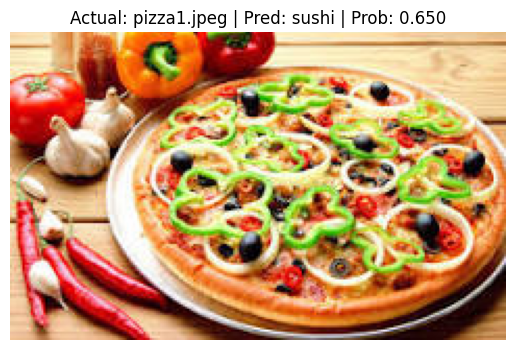

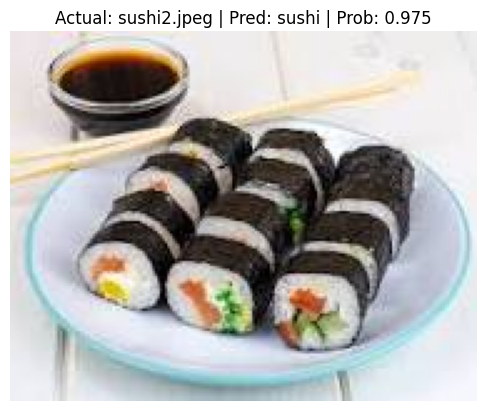

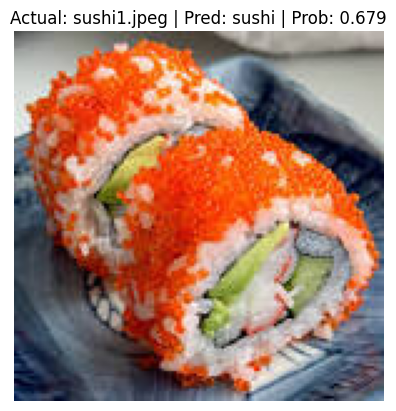

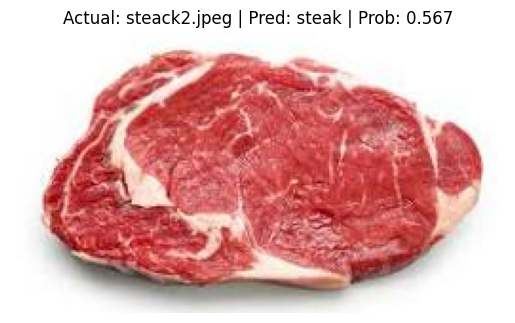

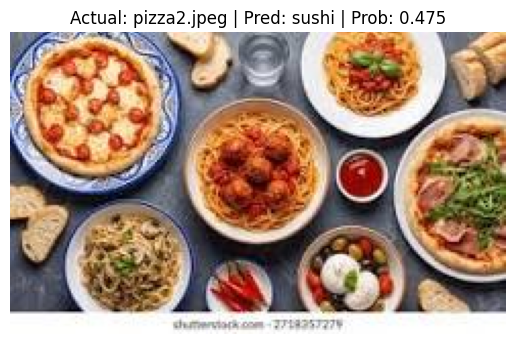

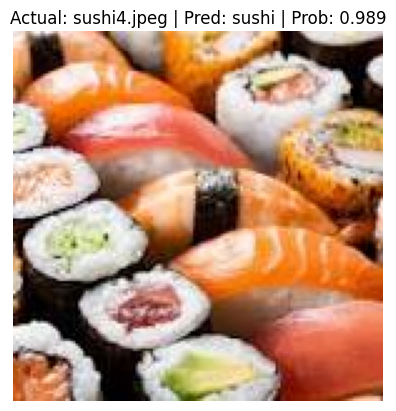

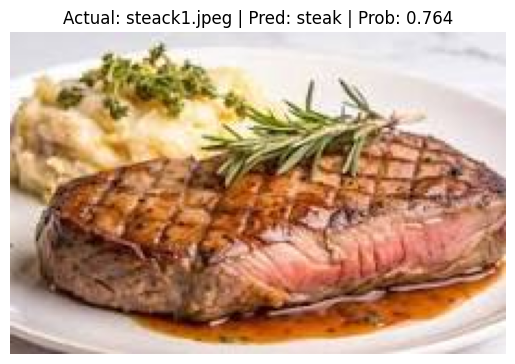

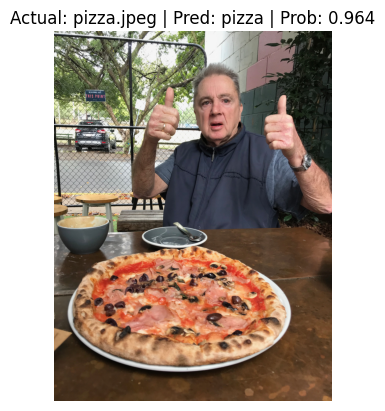

In [48]:
# predict on custom image
evaluation = importlib.reload(evaluation)

img_path = custom_image_path.parent
for img in img_path.iterdir():
    evaluation.pred_and_plot_image(
        model=best_model,
        class_names=class_names,
        image_path=img
    )

Note: but some the model are strugle to predict pizza(two actually pizza images are predicted as sushi) and the others are nice(even predicting sushi are certainly perfect the problablity are 98.9% sure.)